In [1]:
# Step 1

from google.colab import drive
import pandas as pd

drive.mount('/content/drive')

file_path = "/content/drive/MyDrive/Smart_Campus_Analytics/Cleaned_Student_Dataset.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully.")
print("Shape:", df.shape)

Mounted at /content/drive
Dataset loaded successfully.
Shape: (300, 15)


In [2]:
# Step 2

total_students = len(df)

placed_students = (df["Placement_Status"] == "Placed").sum()
not_placed_students = (df["Placement_Status"] == "Not Placed").sum()

placement_percentage = (placed_students / total_students) * 100
not_placement_percentage = (not_placed_students / total_students) * 100

print("Total Students:", total_students)
print("Placed Students:", placed_students)
print("Not Placed Students:", not_placed_students)
print("Placement Percentage:", round(placement_percentage, 2), "%")
print("Not Placed Percentage:", round(not_placement_percentage, 2), "%")

Total Students: 300
Placed Students: 250
Not Placed Students: 50
Placement Percentage: 83.33 %
Not Placed Percentage: 16.67 %


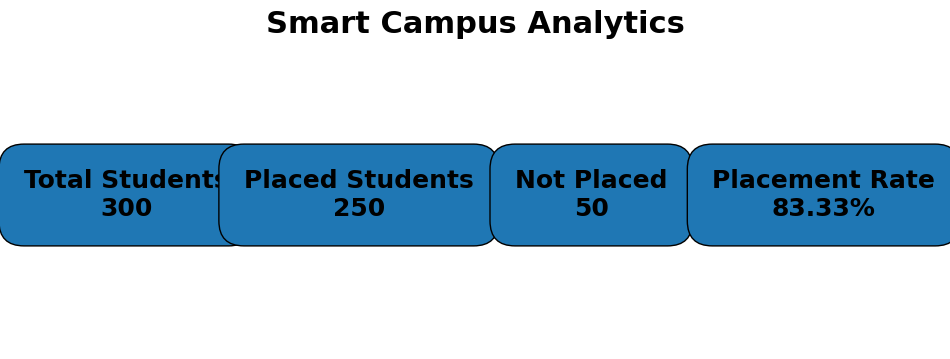

In [3]:
# Step 3

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 4))

ax.axis("off")

kpis = [
    ("Total Students", total_students),
    ("Placed Students", placed_students),
    ("Not Placed", not_placed_students),
    ("Placement Rate", f"{placement_percentage:.2f}%")
]

for i, (title, value) in enumerate(kpis):
    ax.text(
        0.125 + i * 0.25,
        0.5,
        f"{title}\n{value}",
        ha="center",
        va="center",
        fontsize=18,
        fontweight="bold",
        bbox=dict(boxstyle="round,pad=1")
    )

plt.title("Smart Campus Analytics", fontsize=22, fontweight="bold")
plt.show()

In [6]:
# Step 4

import plotly.express as px
import ipywidgets as widgets
from IPython.display import display, clear_output

department_filter = widgets.Dropdown(
    options=["All"] + sorted(df["Department"].unique().tolist()),
    value="All",
    description="Department:"
)

gender_filter = widgets.Dropdown(
    options=["All"] + sorted(df["Gender"].unique().tolist()),
    value="All",
    description="Gender:"
)

internship_filter = widgets.Dropdown(
    options=["All"] + sorted(df["Internship"].unique().tolist()),
    value="All",
    description="Internship:"
)

output = widgets.Output()

display(
    department_filter,
    gender_filter,
    internship_filter,
    output
)

Dropdown(description='Department:', options=('All', 'Business Administration', 'Civil', 'Computer Science', 'C…

Dropdown(description='Gender:', options=('All', 'Female', 'Male'), value='All')

Dropdown(description='Internship:', options=('All', 'No', 'Yes'), value='All')

Output()

In [9]:
# Step 5

def update_dashboard(department, gender, internship):
    with output:
        clear_output(wait=True)

        filtered_df = df.copy()

        if department != "All":
            filtered_df = filtered_df[
                filtered_df["Department"] == department
            ]

        if gender != "All":
            filtered_df = filtered_df[
                filtered_df["Gender"] == gender
            ]

        if internship != "All":
            filtered_df = filtered_df[
                filtered_df["Internship"] == internship
            ]

        total = len(filtered_df)
        placed = (filtered_df["Placement_Status"] == "Placed").sum()
        not_placed = (filtered_df["Placement_Status"] == "Not Placed").sum()

        rate = (placed / total * 100) if total > 0 else 0

        print("SMART CAMPUS ANALYTICS")
        print("=====================")
        print("Total Students:", total)
        print("Placed Students:", placed)
        print("Not Placed Students:", not_placed)
        print("Placement Rate:", round(rate, 2), "%")

        placement_data = (
            filtered_df["Placement_Status"]
            .value_counts()
            .reset_index()
        )

        fig1 = px.bar(
            placement_data,
            x="Placement_Status",
            y="count",
            title="Placement Status"
        )
        fig1.show()

        dept_data = pd.crosstab(
            filtered_df["Department"],
            filtered_df["Placement_Status"]
        ).reset_index()

        fig2 = px.bar(
            dept_data,
            x="Department",
            y=["Placed", "Not Placed"],
            barmode="group",
            title="Department-wise Placement"
        )
        fig2.show()

        fig3 = px.box(
            filtered_df,
            x="Placement_Status",
            y="CGPA",
            title="CGPA vs Placement"
        )
        fig3.show()

        fig4 = px.box(
            filtered_df,
            x="Placement_Status",
            y="Attendance_%",
            title="Attendance vs Placement"
        )
        fig4.show()

        backlog_data = (
            filtered_df.groupby(
                ["Backlogs", "Placement_Status"]
            ).size().reset_index(name="Students")
        )

        fig5 = px.bar(
            backlog_data,
            x="Backlogs",
            y="Students",
            color="Placement_Status",
            barmode="group",
            title="Backlogs vs Placement"
        )
        fig5.show()

        skills_data = (
            filtered_df.groupby(
                ["Skills", "Placement_Status"]
            ).size().reset_index(name="Students")
        )

        fig6 = px.bar(
            skills_data,
            x="Skills",
            y="Students",
            color="Placement_Status",
            barmode="group",
            title="Skills vs Placement"
        )
        fig6.show()


department_filter.observe(
    lambda change: update_dashboard(
        department_filter.value,
        gender_filter.value,
        internship_filter.value
    ),
    names="value"
)

gender_filter.observe(
    lambda change: update_dashboard(
        department_filter.value,
        gender_filter.value,
        internship_filter.value
    ),
    names="value"
)

internship_filter.observe(
    lambda change: update_dashboard(
        department_filter.value,
        gender_filter.value,
        internship_filter.value
    ),
    names="value"
)

update_dashboard(
    department_filter.value,
    gender_filter.value,
    internship_filter.value
)

In [10]:
# Step 6

import plotly.express as px
from IPython.display import display

filtered_df = df.copy()

total = len(filtered_df)
placed = (filtered_df["Placement_Status"] == "Placed").sum()
not_placed = (filtered_df["Placement_Status"] == "Not Placed").sum()
rate = placed / total * 100

print("SMART CAMPUS ANALYTICS")
print("=====================")
print("Total Students:", total)
print("Placed Students:", placed)
print("Not Placed Students:", not_placed)
print("Placement Rate:", round(rate, 2), "%")

fig1 = px.pie(
    filtered_df,
    names="Placement_Status",
    title="Overall Placement Status"
)

fig1.show()

fig2 = px.bar(
    filtered_df,
    x="Department",
    color="Placement_Status",
    barmode="group",
    title="Department-wise Placement"
)

fig2.show()

fig3 = px.box(
    filtered_df,
    x="Placement_Status",
    y="CGPA",
    title="CGPA vs Placement"
)

fig3.show()

fig4 = px.box(
    filtered_df,
    x="Placement_Status",
    y="Attendance_%",
    title="Attendance vs Placement"
)

fig4.show()

fig5 = px.bar(
    filtered_df,
    x="Backlogs",
    color="Placement_Status",
    barmode="group",
    title="Backlogs vs Placement"
)

fig5.show()

fig6 = px.bar(
    filtered_df,
    x="Skills",
    color="Placement_Status",
    barmode="group",
    title="Skills vs Placement"
)

fig6.show()

SMART CAMPUS ANALYTICS
Total Students: 300
Placed Students: 250
Not Placed Students: 50
Placement Rate: 83.33 %


In [11]:
# Step 7

average_cgpa = df["CGPA"].mean()
average_attendance = df["Attendance_%"].mean()
average_backlogs = df["Backlogs"].mean()

internship_students = (
    df["Internship"] == "Yes"
).sum()

internship_rate = (
    internship_students / total_students
) * 100

placed_df = df[df["Placement_Status"] == "Placed"]

average_package = placed_df["Package_LPA"].mean()

print("SMART CAMPUS ANALYTICS - KEY INSIGHTS")
print("=====================================")
print("Total Students:", total_students)
print("Placed Students:", placed_students)
print("Not Placed Students:", not_placed_students)
print("Placement Rate:", round(placement_percentage, 2), "%")
print("Average CGPA:", round(average_cgpa, 2))
print("Average Attendance:", round(average_attendance, 2), "%")
print("Average Backlogs:", round(average_backlogs, 2))
print("Internship Rate:", round(internship_rate, 2), "%")
print("Average Package:", round(average_package, 2), "LPA")
print("ML Model Accuracy:", "93.33%")

SMART CAMPUS ANALYTICS - KEY INSIGHTS
Total Students: 300
Placed Students: 250
Not Placed Students: 50
Placement Rate: 83.33 %
Average CGPA: 7.59
Average Attendance: 78.63 %
Average Backlogs: 0.65
Internship Rate: 59.67 %
Average Package: 6.63 LPA
ML Model Accuracy: 93.33%


In [12]:
# Step 8

import plotly.express as px

department_data = (
    df.groupby(["Department", "Placement_Status"])
    .size()
    .reset_index(name="Students")
)

fig1 = px.bar(
    department_data,
    x="Department",
    y="Students",
    color="Placement_Status",
    barmode="group",
    title="Department-wise Placement"
)

fig1.show()


gender_data = (
    df.groupby(["Gender", "Placement_Status"])
    .size()
    .reset_index(name="Students")
)

fig2 = px.bar(
    gender_data,
    x="Gender",
    y="Students",
    color="Placement_Status",
    barmode="group",
    title="Gender-wise Placement"
)

fig2.show()


age_data = (
    df.groupby(["Age", "Placement_Status"])
    .size()
    .reset_index(name="Students")
)

fig3 = px.bar(
    age_data,
    x="Age",
    y="Students",
    color="Placement_Status",
    barmode="group",
    title="Age-wise Placement"
)

fig3.show()

In [13]:
# Step 9

import plotly.express as px

internship_data = (
    df.groupby(["Internship", "Placement_Status"])
    .size()
    .reset_index(name="Students")
)

fig1 = px.bar(
    internship_data,
    x="Internship",
    y="Students",
    color="Placement_Status",
    barmode="group",
    title="Internship vs Placement"
)
fig1.show()


backlog_data = (
    df.groupby(["Backlogs", "Placement_Status"])
    .size()
    .reset_index(name="Students")
)

fig2 = px.bar(
    backlog_data,
    x="Backlogs",
    y="Students",
    color="Placement_Status",
    barmode="group",
    title="Backlogs vs Placement"
)
fig2.show()


skills_data = (
    df.groupby(["Skills", "Placement_Status"])
    .size()
    .reset_index(name="Students")
)

fig3 = px.bar(
    skills_data,
    x="Skills",
    y="Students",
    color="Placement_Status",
    barmode="group",
    title="Skills vs Placement"
)

fig3.update_layout(xaxis_tickangle=-45)
fig3.show()


placed_data = df[df["Placement_Status"] == "Placed"]

fig4 = px.histogram(
    placed_data,
    x="Package_LPA",
    nbins=15,
    title="Package Distribution of Placed Students"
)

fig4.show()

In [16]:
# Step 10

total_students = len(df)

placed_students = (
    df["Placement_Status"] == "Placed"
).sum()

not_placed_students = (
    df["Placement_Status"] == "Not Placed"
).sum()

placement_rate = (
    placed_students / total_students
) * 100

average_cgpa = df["CGPA"].mean()

average_attendance = df["Attendance_%"].mean()

average_backlogs = df["Backlogs"].mean()

internship_students = (
    df["Internship"] == "Yes"
).sum()

internship_rate = (
    internship_students / total_students
) * 100

placed_df = df[
    df["Placement_Status"] == "Placed"
]

average_package = placed_df["Package_LPA"].mean()


print("=" * 60)
print("        SMART CAMPUS ANALYTICS")
print("        FINAL DASHBOARD SUMMARY")
print("=" * 60)

print(f"Total Students       : {total_students}")
print(f"Placed Students      : {placed_students}")
print(f"Not Placed Students  : {not_placed_students}")
print(f"Placement Rate       : {placement_rate:.2f}%")
print(f"Average CGPA         : {average_cgpa:.2f}")
print(f"Average Attendance   : {average_attendance:.2f}%")
print(f"Average Backlogs     : {average_backlogs:.2f}")
print(f"Internship Rate      : {internship_rate:.2f}%")
print(f"Average Package      : {average_package:.2f} LPA")

print("=" * 60)
print("KEY FINDINGS")
print("=" * 60)

print(f"1. {placement_rate:.2f}% students are placed.")
print(f"2. {not_placed_students} students are not placed.")
print(f"3. Average CGPA is {average_cgpa:.2f}.")
print(f"4. Average attendance is {average_attendance:.2f}%.")
print(f"5. Internship participation is {internship_rate:.2f}%.")
print(f"6. Average package of placed students is {average_package:.2f} LPA.")
print("=" * 60)

        SMART CAMPUS ANALYTICS
        FINAL DASHBOARD SUMMARY
Total Students       : 300
Placed Students      : 250
Not Placed Students  : 50
Placement Rate       : 83.33%
Average CGPA         : 7.59
Average Attendance   : 78.63%
Average Backlogs     : 0.65
Internship Rate      : 59.67%
Average Package      : 6.63 LPA
KEY FINDINGS
1. 83.33% students are placed.
2. 50 students are not placed.
3. Average CGPA is 7.59.
4. Average attendance is 78.63%.
5. Internship participation is 59.67%.
6. Average package of placed students is 6.63 LPA.
